- 2D Skewness and Kurtosis map. 

- Variance to mean ratio and Variance to median ratio


In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors

# import imageio # to collect frames and write them into an animated file.
# import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])

from typing import Optional

from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from concurrent.futures import ProcessPoolExecutor


# Load and convert the data to xarray


Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5

EDD_2023-08-09T19_46_45.289915UTC_viGdg.hdf5

In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
# dirname = filename.split('.')[0]

# to_save = False

In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency}
        )

        datasets[g] = ds

In [4]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [5]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:    (time: 634, frequency: 63877)
Coordinates:
  * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
  * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
Data variables:
    spectrum   (time, frequency) float32 162MB 1.883e+11 1.862e+11 ... 4.159e+09

Text(0.5, 1.0, 'Dynamic Spectrum for scan_000_P1_ND0')

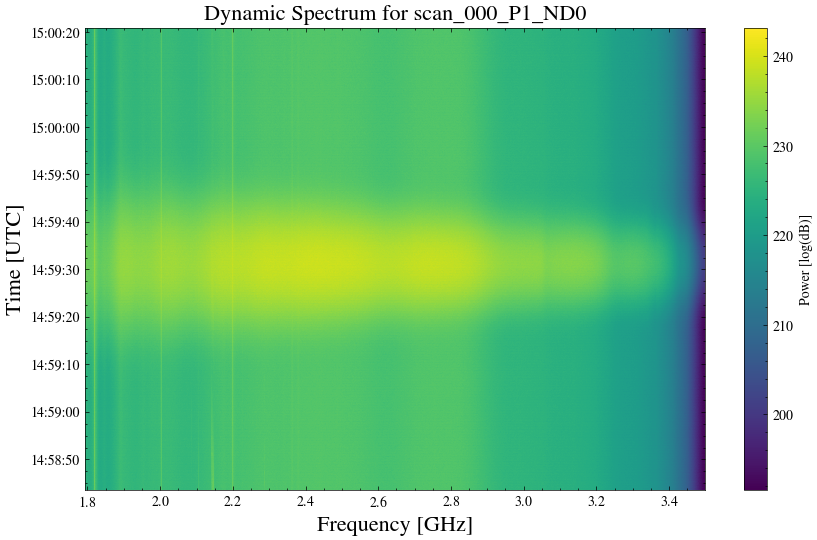

In [ ]:
# defie the variables
spectrum = data['spectrum']
frequency = data['frequency']
time = data['time']




# Spectrum to dB
spectrum_db = (10*np.log10(spectrum**2))


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)



#plot the dynamic spectrum
plt.figure(figsize=(10, 6))
plt.pcolormesh(frequency, time_utc, spectrum_db, shading='auto', cmap='viridis')
plt.colorbar(label='Power [log(dB)]')
plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Time [UTC]', fontsize=16)
plt.title(f'Dynamic Spectrum for {scan_name}', fontsize=16)

In [7]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

In [9]:
results = variance_to_median_square_ratio_single_dish(spectrum_db, time_dim='time', freq_dim='frequency')
results

<xarray.Dataset> Size: 2MB
Dimensions:       (frequency: 63877)
Coordinates:
  * frequency     (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498
Data variables:
    median        (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>
    variance      (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r          (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_by_freq  (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_global   float32 4B 0.0001844

In [10]:
vm2r = results["vm2r_by_freq"].values

vm2r

array([0.00010951, 0.000109  , 0.00010966, ..., 0.00019895, 0.00019835,
       0.00019713], shape=(63877,), dtype=float32)

In [11]:
vm2r.max()/vm2r.min()

np.float32(19.23097)

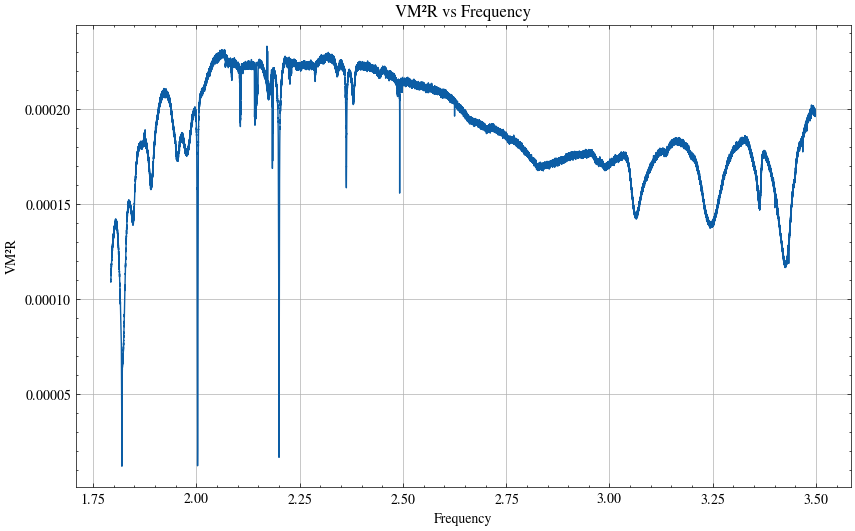

In [12]:

vm2r_freq = results["vm2r"]

plt.figure(figsize=(10, 6))
plt.plot(vm2r_freq['frequency'], vm2r_freq)
plt.xlabel("Frequency")
plt.ylabel("VM²R")
plt.title("VM²R vs Frequency")
plt.grid()
plt.show()

In [13]:
spectrum_db_mean = spectrum_db.mean(dim='time')
spectrum_db_mean.shape

(63877,)

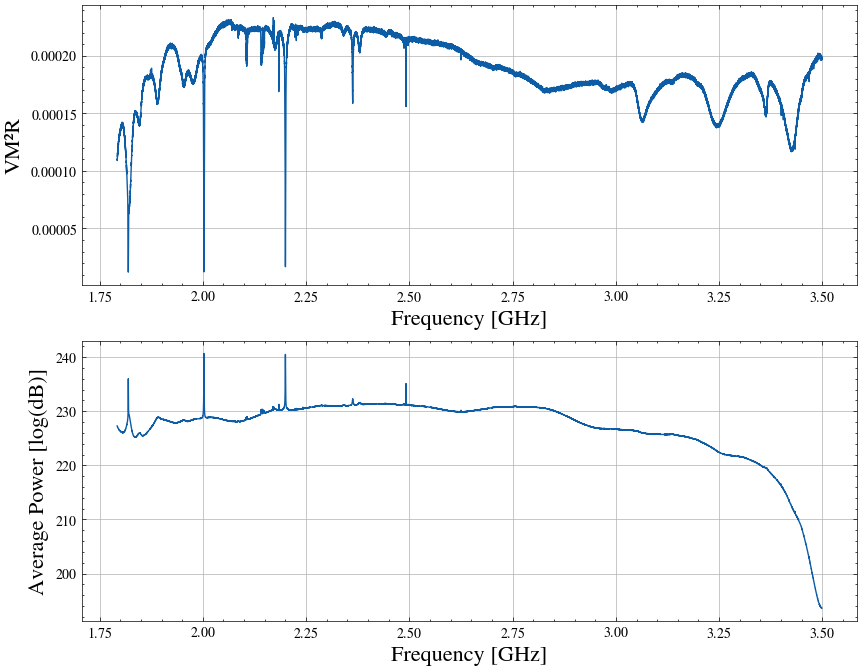

In [14]:
fig, ax = plt.subplots(2,1,figsize=(10, 8))
ax[0].plot(vm2r_freq['frequency'], vm2r_freq)
ax[0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0].set_ylabel("VM²R",fontsize=16)
ax[0].grid()
#ax[0].set_title("VM²R vs Frequency")

ax[1].plot(frequency, spectrum_db_mean)
ax[1].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1].grid()
#ax[1].set_title("Mean Spectrum vs Frequency")

# Aply the flag on the peaks  and perform VM2R just to compare the information

In [15]:
# Isolate the skipe high prominent RFI signals

mask1 = (frequency > 1.8162) & (frequency < 1.8272) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask2 = (frequency > 1.8735) & (frequency < 1.8737) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask3 = (frequency > 2.0004) & (frequency < 2.0052) # Mobile Satellite Uplink (Earth to Space)
mask4 = (frequency > 2.0920) & (frequency < 2.0959) # Space Operations (Earth to Space and vice versa)
mask5 = (frequency > 2.1975) & (frequency < 2.2024) # Mobile Satellite Downlink (Space to Earth)
mask6 = (frequency > 2.3605) & (frequency < 2.3658) # Fixed Wireless Access Point to Point/Point to Multipoint #5G
mask7 = (frequency > 2.4916) & (frequency < 2.4925) # Mobile Satellite Services # ITU Resolution 249 (Rev.WRC‑23);
mask8 = (frequency > 2.6250) & (frequency < 2.6250) # ICASA (Independent Communications Authority of South Africa) Frequency Plan ???

mask = mask1 | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask8

In [16]:
spectrum_db.shape

(634, 63877)

In [17]:

mask_signal = spectrum_db[:,~mask]
mask_signal_mean = mask_signal.mean(dim='time')

mask_signal.shape, frequency[~mask].shape, mask_signal_mean.shape

((634, 62716), (62716,), (62716,))

In [18]:
# perform the VM2R
results2 = variance_to_median_square_ratio_single_dish(mask_signal, time_dim='time', freq_dim='frequency')
results2

<xarray.Dataset> Size: 2MB
Dimensions:       (frequency: 62716)
Coordinates:
  * frequency     (frequency) float64 502kB 1.793 1.793 1.793 ... 3.498 3.498
Data variables:
    median        (frequency) float32 251kB dask.array<chunksize=(62716,), meta=np.ndarray>
    variance      (frequency) float32 251kB dask.array<chunksize=(62716,), meta=np.ndarray>
    vm2r          (frequency) float32 251kB dask.array<chunksize=(62716,), meta=np.ndarray>
    vm2r_by_freq  (frequency) float32 251kB dask.array<chunksize=(62716,), meta=np.ndarray>
    vm2r_global   float32 4B 0.0001847

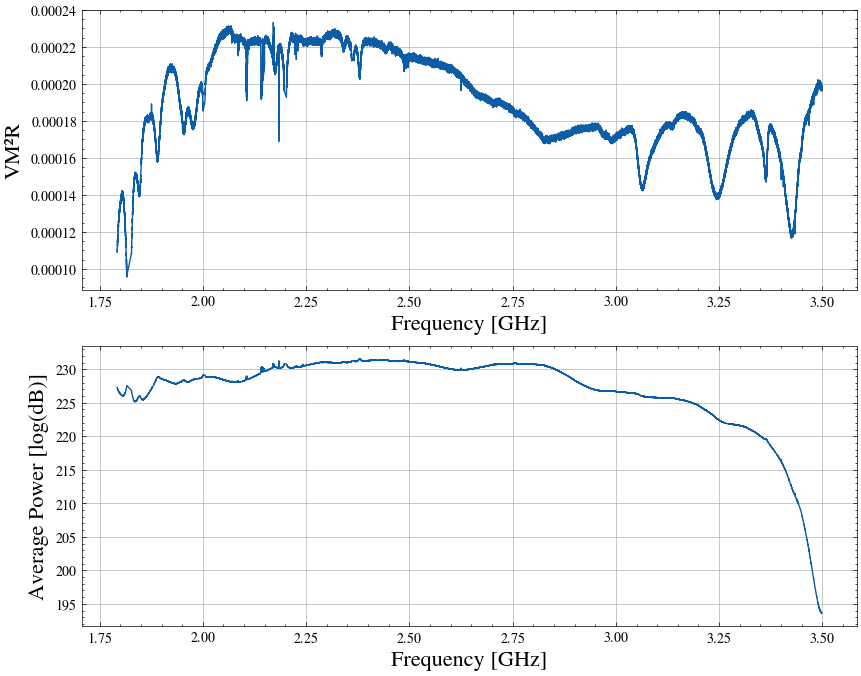

In [19]:
fig, ax = plt.subplots(2,1,figsize=(10, 8))
ax[0].plot(results2['frequency'], results2['vm2r'])
ax[0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0].set_ylabel("VM²R",fontsize=16)
ax[0].grid()
#ax[0].set_title("VM²R vs Frequency")

ax[1].plot(frequency[~mask], mask_signal_mean)
ax[1].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1].grid()
#ax[1].set_title("Mean Spectrum vs Frequency")

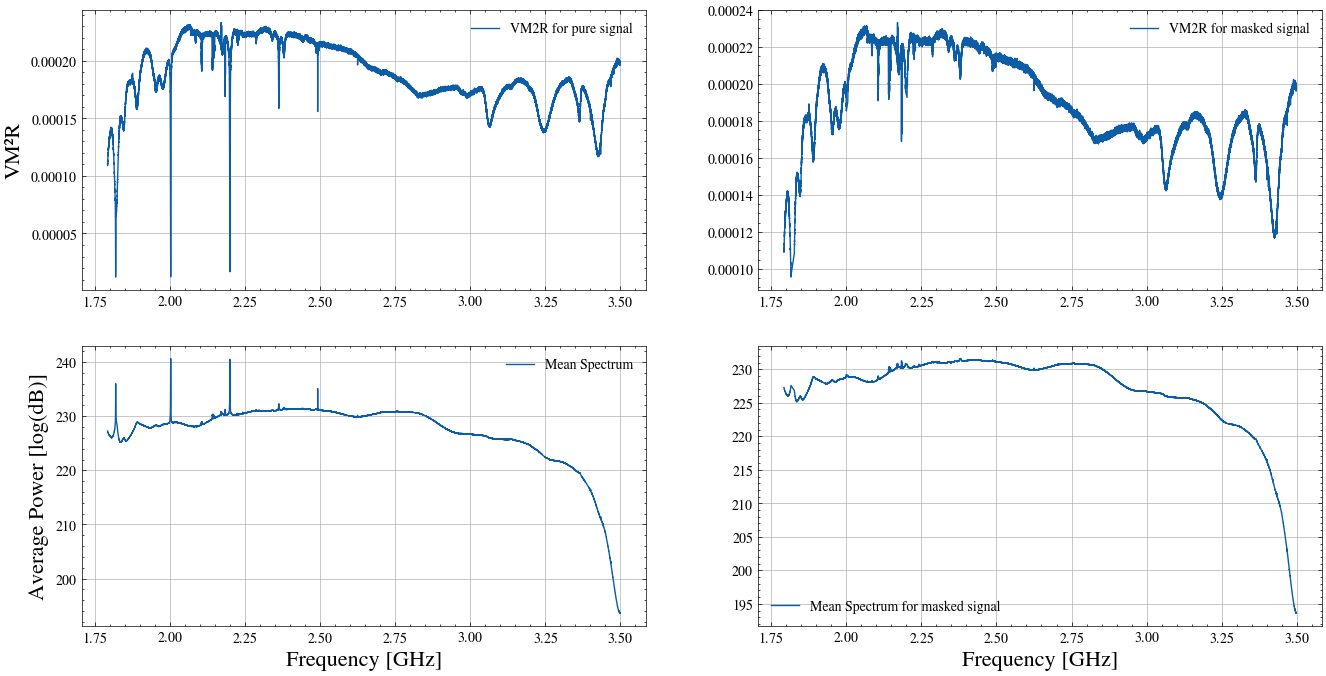

In [20]:
fig, ax = plt.subplots(2,2,figsize=(16, 8))

ax[0,0].plot(vm2r_freq['frequency'], vm2r_freq, label="VM2R for pure signal")
#ax[0,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0,0].set_ylabel("VM²R",fontsize=16)
ax[0,0].grid()
ax[0,0].legend()

ax[1,0].plot(frequency, spectrum_db_mean, label="Mean Spectrum")
ax[1,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1,0].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1,0].grid()
ax[1,0].legend()


ax[0,1].plot(results2['frequency'], results2['vm2r'], label="VM2R for masked signal")
#ax[0,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[0,1].set_ylabel("VM²R",fontsize=16)
ax[0,1].grid()
ax[0,1].legend()

ax[1,1].plot(frequency[~mask], mask_signal_mean, label="Mean Spectrum for masked signal")
ax[1,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[1,1].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1,1].grid()
ax[1,1].legend()

In [21]:
# detrending the spectrum 
corrected_spectrum = base_correction(frequency, spectrum_db_mean)
corrected_spectrum.shape

(63877,)

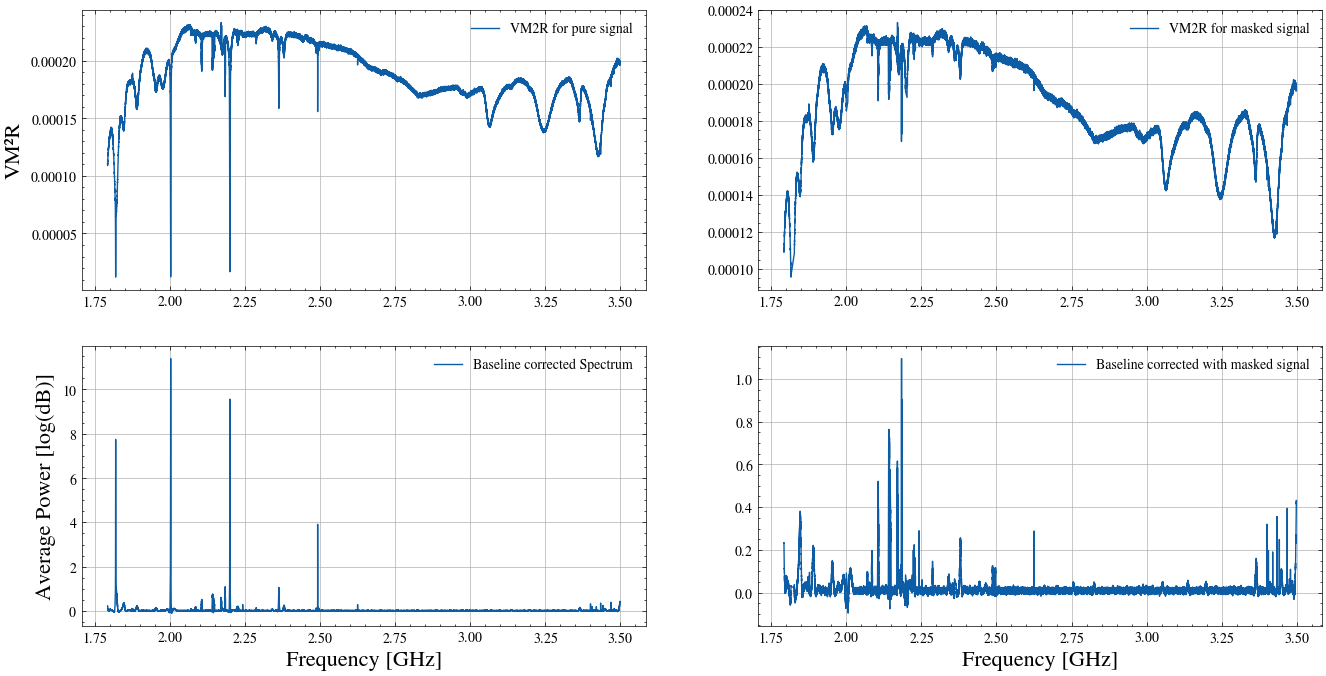

In [22]:
fig, ax = plt.subplots(2,2,figsize=(16, 8))

ax[0,0].plot(vm2r_freq['frequency'], vm2r_freq, label="VM2R for pure signal")
#ax[0,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0,0].set_ylabel("VM²R",fontsize=16)
ax[0,0].grid()
ax[0,0].legend()

ax[1,0].plot(frequency, corrected_spectrum, label="Baseline corrected Spectrum")
ax[1,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1,0].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1,0].grid()
ax[1,0].legend()


ax[0,1].plot(results2['frequency'], results2['vm2r'], label="VM2R for masked signal")
#ax[0,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[0,1].set_ylabel("VM²R",fontsize=16)
ax[0,1].grid()
ax[0,1].legend()

ax[1,1].plot(frequency[~mask], corrected_spectrum[~mask], label="Baseline corrected with masked signal")
ax[1,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[1,1].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1,1].grid()
ax[1,1].legend()

In [23]:
(results2['vm2r_by_freq'].max()/results2['vm2r_by_freq'].min()).compute()

<xarray.DataArray 'vm2r_by_freq' ()> Size: 4B
array(2.4403455, dtype=float32)

In [24]:
vm2r.max()/vm2r.min()

np.float32(19.23097)

In [26]:
def robust_skew_kurt_2d(
    time_dim: str = "time",
    freq_dim: str = "freq",
    dim_axis: str = "time",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Robust skewness and kurtosis maps over (time, freq) using median/MAD.

    Returns
    -------
    xr.Dataset with:
      - skewness: robust skewness per (freq[, pol])
      - kurtosis: robust excess kurtosis per (freq[, pol])
    """

    # Handle Dataset
    if isinstance(obj, xr.Dataset):
        obj = obj[list(obj.data_vars)[0]]

    dims = [dim_axis]
    if pol_dim and pol_dim in obj.dims:
        dims = [dim_axis]

    x = obj.chunk({dim_axis: -1})

    # Robust location & scale
    med = x.median(dim=dim_axis, skipna=True)
    mad = (np.abs(x - med)).median(dim=dim_axis, skipna=True)
    sigma = 1.4826 * mad

    # Avoid division by zero
    sigma = xr.where(sigma < eps, np.nan, sigma)

    # Standardised residuals
    z = (x - med) / sigma

    # Robust moments
    skew = (z**3).mean(dim=dim_axis, skipna=True).rename("skewness")
    kurt = (z**4).mean(dim=dim_axis, skipna=True) - 3.0
    kurt = kurt.rename("kurtosis")

    return xr.Dataset({
        "skewness": skew,
        "kurtosis": kurt
    })


In [27]:
spec = spectrum_db/ spectrum_db.mean(dim='time')

robust_2d = robust_skew_kurt_2d(spec, time_dim='time', freq_dim='frequency')
robust_2d

TypeError: robust_skew_kurt_2d() got multiple values for argument 'time_dim'

In [28]:
skew = robust_2d['skewness'].values
skew.shape

NameError: name 'robust_2d' is not defined

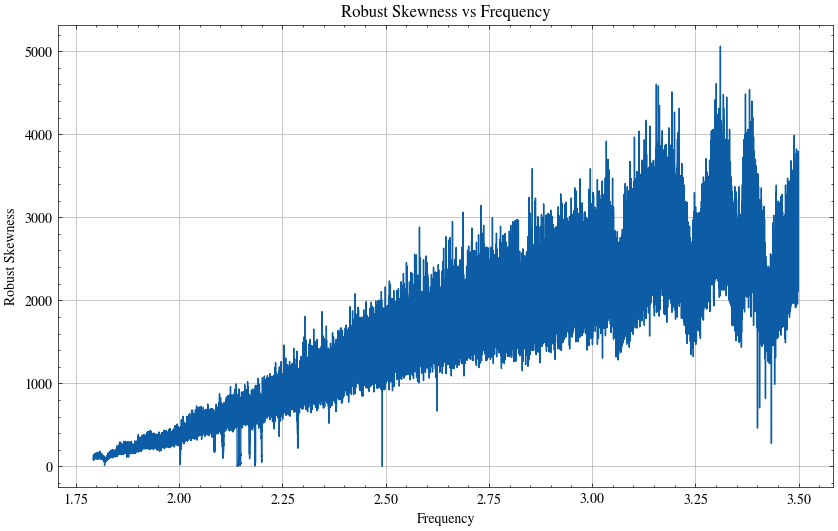

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d['frequency'], robust_2d['skewness'])
plt.xlabel("Frequency")
plt.ylabel("Robust Skewness")
plt.title("Robust Skewness vs Frequency")
plt.grid()
plt.show()

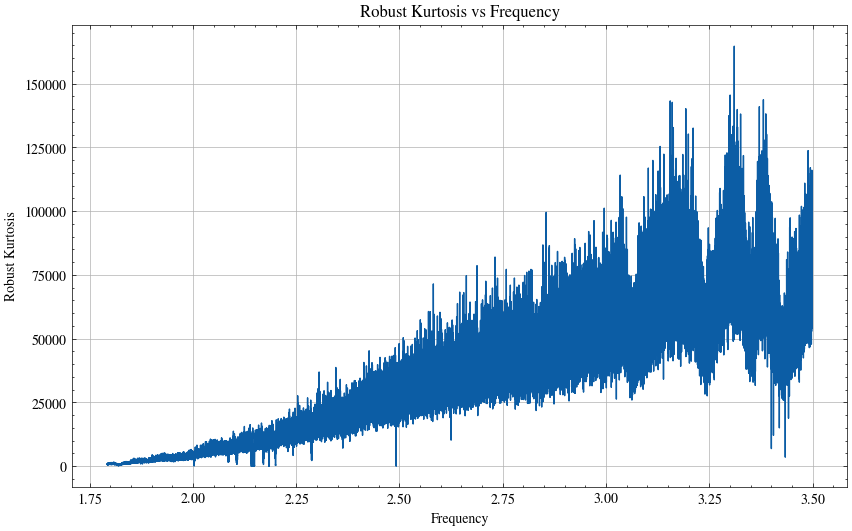

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d['frequency'], robust_2d['kurtosis'])
plt.xlabel("Frequency")
plt.ylabel("Robust Kurtosis")
plt.title("Robust Kurtosis vs Frequency")
plt.grid()
plt.show()

In [ ]:
robust_2d_time = robust_skew_kurt_2d(spectrum_db, dim_axis='frequency')
robust_2d_time

<xarray.Dataset> Size: 10kB
Dimensions:   (time: 634)
Coordinates:
  * time      (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
Data variables:
    skewness  (time) float32 3kB dask.array<chunksize=(634,), meta=np.ndarray>
    kurtosis  (time) float32 3kB dask.array<chunksize=(634,), meta=np.ndarray>

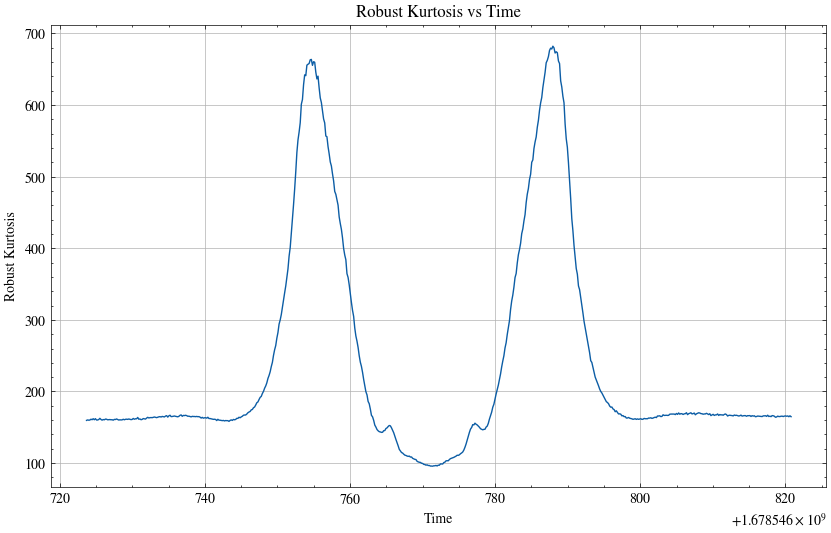

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d_time['time'], robust_2d_time['kurtosis'])
plt.xlabel("Time")
plt.ylabel("Robust Kurtosis")
plt.title("Robust Kurtosis vs Time")
plt.grid()
plt.show()

In [ ]:
robust_2d_frequency = robust_skew_kurt_2d(spectrum_db, dim_axis='time')
robust_2d_frequency

<xarray.Dataset> Size: 1MB
Dimensions:    (frequency: 63877)
Coordinates:
  * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
Data variables:
    skewness   (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>
    kurtosis   (frequency) float32 256kB dask.array<chunksize=(63877,), meta=np.ndarray>

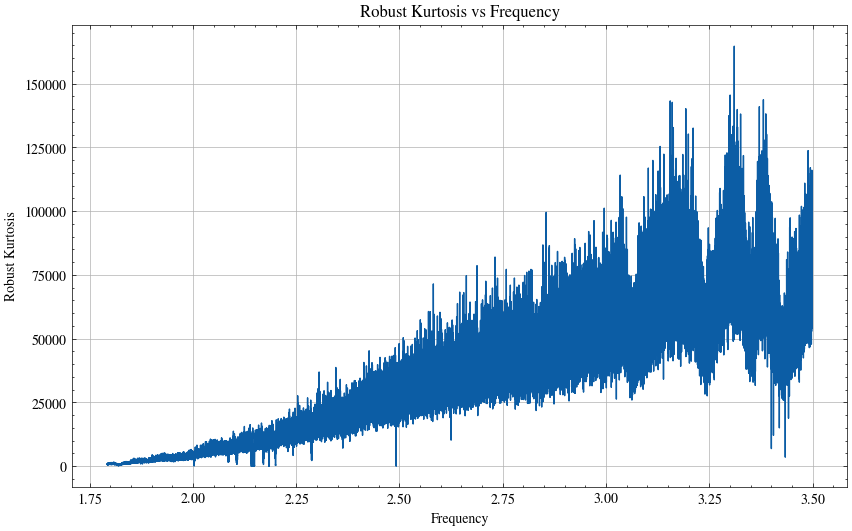

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d_frequency['frequency'], robust_2d_frequency['kurtosis'])
plt.xlabel("Frequency")
plt.ylabel("Robust Kurtosis")
plt.title("Robust Kurtosis vs Frequency")
plt.grid()
plt.show()

# Perform the kusrtosis and Skewness

<Axes: ylabel='Density'>

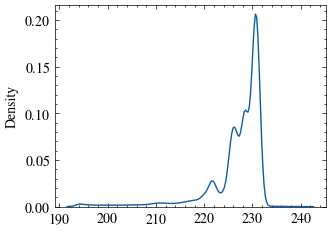

In [ ]:
sns.kdeplot(spectrum_db_mean, label="Spectrum mean distribution")



<Axes: ylabel='Density'>

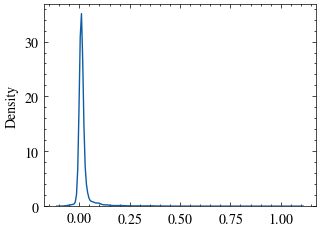

In [ ]:
sns.kdeplot(corrected_spectrum[~mask], label="Spectrum mean distribution")

In [ ]:

def generate_gaussian_xarray(
    n_time=500,
    n_freq=256,
    time_start=0.0,
    time_step=1.0,
    freq_start=1.0,
    freq_step=0.01,
    mean=0.0,
    std=1.0,
    seed=None,
):
    """
    Generate a 2D Gaussian (normal) xarray DataArray with dimensions (time, freq).
    """

    if seed is not None:
        np.random.seed(seed)

    # Coordinates
    time = time_start + np.arange(n_time) * time_step
    freq = freq_start + np.arange(n_freq) * freq_step

    # Gaussian noise
    data = np.random.normal(loc=mean, scale=std, size=(n_time, n_freq))

    # Build xarray
    da = xr.DataArray(
        data,
        dims=("time", "freq"),
        coords={"time": time, "freq": freq},
        name="gaussian_noise",
        attrs={
            "description": "2D Gaussian random field",
            "mean": mean,
            "std": std,
        },
    )

    return da

<xarray.DataArray 'gaussian_noise' (time: 500, freq: 256)> Size: 1MB
array([[ 0.49671415, -0.1382643 ,  0.64768854, ...,  1.03246526,
        -1.51936997, -0.48423407],
       [ 1.26691115, -0.70766947,  0.44381943, ..., -0.83095012,
         0.27045683, -0.05023811],
       [-0.23894805, -0.90756366, -0.57677133, ..., -0.70317643,
        -0.03498849,  1.77080064],
       ...,
       [-0.72572845,  1.47279244, -1.17887286, ...,  0.13833821,
         0.99875251, -0.28548397],
       [ 1.72349634, -0.43365452, -0.90072369, ...,  0.76776498,
         1.40241803,  1.79866923],
       [ 1.3854729 , -0.19675095,  0.18888358, ..., -1.68689792,
         0.45281669, -0.37408124]], shape=(500, 256))
Coordinates:
  * time     (time) float64 4kB 0.0 1.0 2.0 3.0 4.0 ... 496.0 497.0 498.0 499.0
  * freq     (freq) float64 2kB 1.0 1.01 1.02 1.03 1.04 ... 3.52 3.53 3.54 3.55
Attributes:
    description:  2D Gaussian random field
    mean:         0.0
    std:          1.0


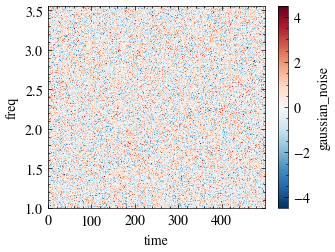

In [ ]:
da = generate_gaussian_xarray(seed=42)

print(da)
da.plot(x="time", y="freq")

In [ ]:
robust_2d_test = robust_skew_kurt_2d(da, time_dim='time', freq_dim='frequency')
robust_2d_test

<xarray.Dataset> Size: 6kB
Dimensions:   (freq: 256)
Coordinates:
  * freq      (freq) float64 2kB 1.0 1.01 1.02 1.03 1.04 ... 3.52 3.53 3.54 3.55
Data variables:
    skewness  (freq) float64 2kB dask.array<chunksize=(256,), meta=np.ndarray>
    kurtosis  (freq) float64 2kB dask.array<chunksize=(256,), meta=np.ndarray>

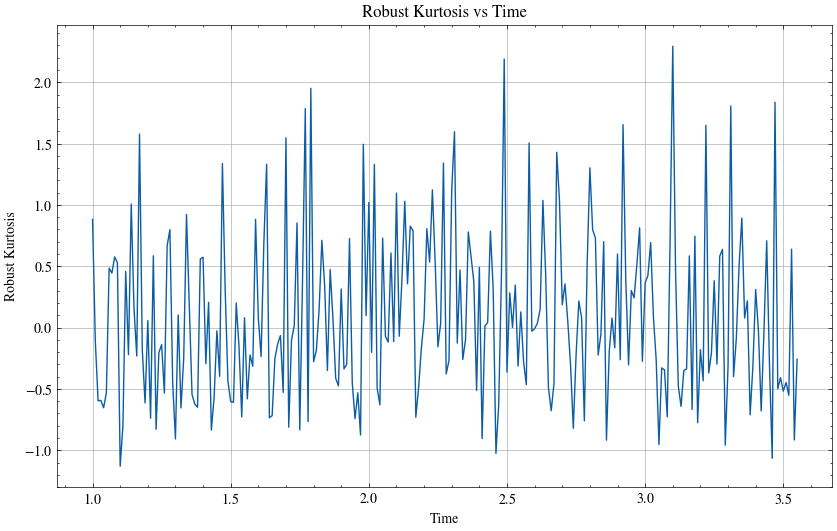

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d_test['freq'], robust_2d_test['kurtosis'])
plt.xlabel("Frequency")
plt.ylabel("Robust Kurtosis")
plt.title("Robust Kurtosis vs Time")
plt.grid()
plt.show()

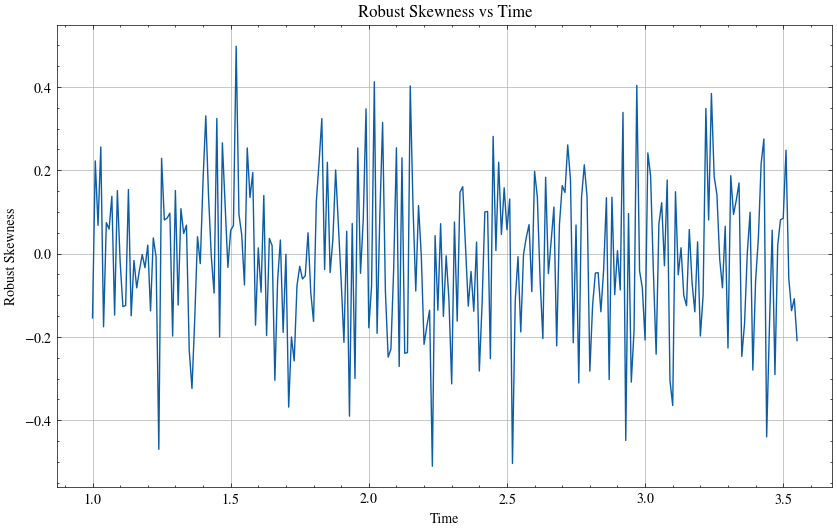

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(robust_2d_test['freq'], robust_2d_test['skewness'])
plt.xlabel("Time")
plt.ylabel("Robust Skewness")
plt.title("Robust Skewness vs Time")
plt.grid()
plt.show()